# 03 · Porównanie modeli klasyfikacji EEG

In [ ]:
from pathlib import Path
import html
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd() 
OUTPUT_DIR = ROOT / "porownanie_modeli"

CSV_FILES = {
    "eegnet": r"/home/eliza/mgr-phd/results_ica_64ch-oba/eegnet/fold_metrics.csv", 
    "cnn_psd": r"/home/eliza/mgr-phd/results_ica_64ch/cnn_psd_fusion/fold_metrics.csv",   
    "csp_lda": r"/home/eliza/mgr-phd/results_ica_64ch-oba/csp_lda/fold_metrics.csv",
    "riemann": r"/home/eliza/mgr-phd/results_ica_64ch-oba/riemann_mdm/fold_metrics.csv",  
}

DISPLAY_NAMES = {
    "eegnet": "EEGNet",
    "cnn_psd": "CNN+PSD (fusion)",
    "csp_lda": "CSP+LDA",
    "riemann": "Riemann",
}

METRICS = [
    "balanced_accuracy", "roc_auc", "accuracy", "f1",
    "precision", "recall", "average_precision",
]
METRIC_LABELS = {
    "balanced_accuracy": "Balanced Accuracy",
    "roc_auc": "ROC AUC",
    "accuracy": "Accuracy",
    "f1": "F1 (lewa)",
    "precision": "Precision (lewa)",
    "recall": "Recall (lewa)",
    "average_precision": "Average Precision",
    "recall_right": "Recall (prawa)",
}

print("Katalog roboczy:", ROOT)
print("Pliki wejściowe mają osobne, ręcznie ustawiane ścieżki.")


Katalog roboczy: /home/eliza/mgr-phd
Pliki wejściowe mają osobne, ręcznie ustawiane ścieżki.


## 2. Wczytanie i kontrola poprawności

In [ ]:
def normalize_header(value):
    txt = html.unescape(str(value)).replace("\ufeff", "")
    txt = txt.strip().strip("*` ").lower()
    return "_".join(txt.replace("-", "_").split())


def locate_csv(model, manual_path):
    """Odczytuje wyłącznie ręcznie wskazany plik; bez automatycznego wyszukiwania."""
    if manual_path is None or not str(manual_path).strip():
        raise ValueError(
            f"Uzupełnij ścieżkę CSV_FILES['{model}'] w komórce 1. "
            "Wpisz pełną ścieżkę do fold_metrics.csv."
        )

    path = Path(manual_path).expanduser()
    if not path.is_absolute():
        path = ROOT / path
    if not path.is_file():
        raise FileNotFoundError(
            f"Nie znaleziono pliku dla '{model}': {path}\n"
            "Sprawdź nazwę, rozszerzenie .csv i uprawnienia dostępu."
        )
    return path.resolve()


def read_model_csv(model, path):
    df = pd.read_csv(path, encoding="utf-8-sig")
    df.columns = [normalize_header(c) for c in df.columns]
    if df.columns.duplicated().any():
        raise ValueError(f"{model}: zduplikowane nagłówki po normalizacji.")
    if "fold" not in df.columns:
        raise ValueError(f"{model}: brakuje kolumny 'fold'.")

    df["fold"] = pd.to_numeric(df["fold"], errors="raise")
    if df["fold"].isna().any() or not (df["fold"] % 1 == 0).all():
        raise ValueError(f"{model}: numer foldu musi być liczbą całkowitą.")
    df["fold"] = df["fold"].astype(int)
    if df["fold"].duplicated().any():
        raise ValueError(f"{model}: wielokrotnie powtórzony numer foldu.")

    available = [m for m in METRICS if m in df.columns]
    if not available:
        raise ValueError(f"{model}: brak rozpoznanych kolumn z metrykami: {METRICS}")
    for m in available:
        df[m] = pd.to_numeric(df[m], errors="raise")
        if df[m].isna().any() or not df[m].between(0, 1).all():
            raise ValueError(f"{model}: metryka '{m}' musi mieć wartości 0–1 bez braków.")
    missing = [m for m in METRICS if m not in df.columns]
    if missing:
        warnings.warn(f"{model}: brak metryk {missing}. Będą pominięte w tych porównaniach.")

    if "n_test" in df.columns:
        df["n_test"] = pd.to_numeric(df["n_test"], errors="raise")
        if df["n_test"].isna().any() or (df["n_test"] <= 0).any():
            raise ValueError(f"{model}: nieprawidłowe 'n_test'.")
    else:
        warnings.warn(f"{model}: brak n_test — nie można zweryfikować liczebności foldów.")

    if {"balanced_accuracy", "recall"}.issubset(df.columns):
        df["recall_right"] = 2 * df["balanced_accuracy"] - df["recall"]
        if not df["recall_right"].between(-0.001, 1.001).all():
            warnings.warn(f"{model}: dziwne Recall prawej; sprawdź etykietę klasy pozytywnej.")
        df["recall_right"] = df["recall_right"].clip(0, 1)
    return df.sort_values("fold").reset_index(drop=True)

paths = {model: locate_csv(model, specified) for model, specified in CSV_FILES.items()}
frames = {model: read_model_csv(model, path) for model, path in paths.items()}

for model, path in paths.items():
    print(f"{DISPLAY_NAMES[model]:<20} → {path} ({len(frames[model])} foldów)")
    if frames[model]["fold"].tolist() != [1, 2, 3, 4, 5]:
        warnings.warn(f"{model}: brak pełnego zestawu foldów 1–5. Porównanie jest niepełne.")

EEGNet               → /home/eliza/mgr-phd/results_ica_64ch-oba/eegnet/fold_metrics.csv (5 foldów)
CNN+PSD (fusion)     → /home/eliza/mgr-phd/results_ica_64ch/cnn_psd_fusion/fold_metrics.csv (5 foldów)
CSP+LDA              → /home/eliza/mgr-phd/results_ica_64ch-oba/csp_lda/fold_metrics.csv (5 foldów)
Riemann              → /home/eliza/mgr-phd/results_ica_64ch-oba/riemann_mdm/fold_metrics.csv (5 foldów)


## 3. Pełne tabele wyników każdego modelu

In [14]:
for model, df in frames.items():
    display(Markdown(f"### {DISPLAY_NAMES[model]}"))
    cols = [c for c in ["fold", "n_test", "n_train_after_aug"] + METRICS + ["recall_right"]
            if c in df.columns]
    formatters = {c: "{:.2%}" for c in cols if c in METRICS + ["recall_right"]}
    if "n_test" in cols:
        formatters["n_test"] = "{:,.0f}"
    if "n_train_after_aug" in cols:
        formatters["n_train_after_aug"] = "{:,.0f}"
    display(df[cols].style.format(formatters, na_rep="—"))

### EEGNet

,fold,n_test,balanced_accuracy,roc_auc,accuracy,f1,precision,recall,average_precision,recall_right
0,1,"1,986",63.94%,68.18%,64.00%,66.51%,62.61%,70.93%,67.56%,56.95%
1,2,"1,914",62.45%,68.50%,62.43%,67.06%,59.66%,76.57%,70.08%,48.33%
2,3,"1,984",60.48%,65.99%,60.33%,55.41%,64.26%,48.71%,66.12%,72.24%
3,4,"1,980",65.14%,70.45%,65.10%,63.65%,67.00%,60.62%,70.55%,69.65%
4,5,"1,980",59.87%,69.06%,59.90%,69.46%,56.12%,91.12%,66.71%,28.61%


### CNN+PSD (fusion)

,fold,n_test,n_train_after_aug,balanced_accuracy,roc_auc,accuracy,f1,precision,recall,average_precision,recall_right
0,1,"1,986","6,241",59.90%,64.69%,59.92%,61.09%,59.81%,62.44%,64.62%,57.36%
1,2,"1,914","6,286",62.92%,68.77%,62.90%,67.55%,59.98%,77.30%,68.23%,48.54%
2,3,"1,984","6,240",61.16%,67.41%,61.09%,58.98%,63.21%,55.28%,68.15%,67.04%
3,4,"1,980","6,247",63.78%,70.02%,63.69%,59.03%,68.43%,51.90%,70.63%,75.66%
4,5,"1,980","6,244",61.29%,67.44%,61.31%,68.35%,57.87%,83.45%,67.00%,39.13%


### CSP+LDA

,fold,n_test,balanced_accuracy,roc_auc,accuracy,f1,precision,recall,average_precision,recall_right
0,1,"1,986",60.58%,64.50%,60.47%,54.96%,64.56%,47.85%,61.01%,73.30%
1,2,"1,914",57.95%,62.01%,57.94%,62.12%,56.46%,69.04%,60.81%,46.87%
2,3,"1,984",58.83%,62.62%,58.87%,60.62%,58.80%,62.55%,60.84%,55.10%
3,4,"1,980",62.34%,66.67%,62.27%,58.98%,65.25%,53.81%,64.40%,70.88%
4,5,"1,980",59.39%,63.61%,59.39%,59.43%,59.43%,59.43%,60.53%,59.35%


### Riemann

,fold,n_test,balanced_accuracy,roc_auc,accuracy,f1,precision,recall,average_precision,recall_right
0,1,"1,986",50.60%,53.18%,50.60%,50.83%,51.01%,50.65%,53.07%,50.56%
1,2,"1,914",51.55%,52.70%,51.57%,40.84%,52.37%,33.47%,52.44%,69.62%
2,3,"1,984",52.66%,54.51%,52.77%,57.04%,52.85%,61.95%,54.28%,43.37%
3,4,"1,980",50.09%,52.75%,49.90%,35.16%,50.56%,26.95%,52.31%,73.22%
4,5,"1,980",50.80%,52.11%,50.81%,53.53%,50.77%,56.61%,52.92%,44.99%


## 4. Zwięzłe porównanie: średnia ± SD z foldów

In [24]:
report_metrics = METRICS + ["recall_right"]
rows = []
for model, df in frames.items():
    record = {"model": model, "n_folds": len(df)}
    if "n_test" in df.columns:
        record["n_test_sum"] = int(df["n_test"].sum())
    for metric in report_metrics:
        record[f"{metric}_mean"] = float(df[metric].mean()) if metric in df else np.nan
        record[f"{metric}_sd"] = float(df[metric].std(ddof=1)) if metric in df else np.nan
    rows.append(record)
summary = pd.DataFrame(rows).set_index("model")
summary = summary.sort_values("balanced_accuracy_mean", ascending=False, na_position="last")

show_metrics = ["balanced_accuracy", "roc_auc", "accuracy", "f1",
                "precision", "recall", "recall_right", "average_precision"]

def pretty_mean_sd(mean, sd):
    if pd.isna(mean):
        return "—"
    if pd.isna(sd):
        return f"{mean*100:.2f}%"
    return f"{mean*100:.2f}% ± {sd*100:.2f} pp"

pretty = pd.DataFrame({
    METRIC_LABELS[m]: [pretty_mean_sd(summary.loc[k, f"{m}_mean"],
                                       summary.loc[k, f"{m}_sd"])
                        for k in summary.index]
    for m in show_metrics
}, index=[DISPLAY_NAMES[k] for k in summary.index])
pretty.index.name = "Model"

display(Markdown("### Ranking: Balanced Accuracy (malejąco)"))
display(pretty)

winner = summary.index[0]
print(f"Najwyższa średnia Balanced Accuracy: {DISPLAY_NAMES[winner]} "
      f"({summary.iloc[0]['balanced_accuracy_mean']:.2%})")

### Ranking: Balanced Accuracy (malejąco)

,Balanced Accuracy,ROC AUC,Accuracy,F1 (lewa),Precision (lewa),Recall (lewa),Recall (prawa),Average Precision
Model,,,,,,,,
EEGNet,62.37% ± 2.24 pp,68.44% ± 1.62 pp,62.35% ± 2.26 pp,64.42% ± 5.44 pp,61.93% ± 4.20 pp,69.59% ± 16.05 pp,55.16% ± 17.72 pp,68.20% ± 2.00 pp
CNN+PSD (fusion),61.81% ± 1.54 pp,67.67% ± 1.99 pp,61.78% ± 1.50 pp,63.00% ± 4.61 pp,61.86% ± 4.14 pp,66.07% ± 13.77 pp,57.55% ± 14.48 pp,67.72% ± 2.18 pp
CSP+LDA,59.82% ± 1.70 pp,63.88% ± 1.82 pp,59.79% ± 1.66 pp,59.22% ± 2.67 pp,60.90% ± 3.83 pp,58.54% ± 8.12 pp,61.10% ± 11.02 pp,61.52% ± 1.62 pp
Riemann,51.14% ± 1.00 pp,53.05% ± 0.90 pp,51.13% ± 1.09 pp,47.48% ± 9.15 pp,51.51% ± 1.03 pp,45.93% ± 15.07 pp,56.35% ± 14.07 pp,53.00% ± 0.78 pp


Najwyższa średnia Balanced Accuracy: EEGNet (62.37%)


## 5. Wizualizacje porównawcze

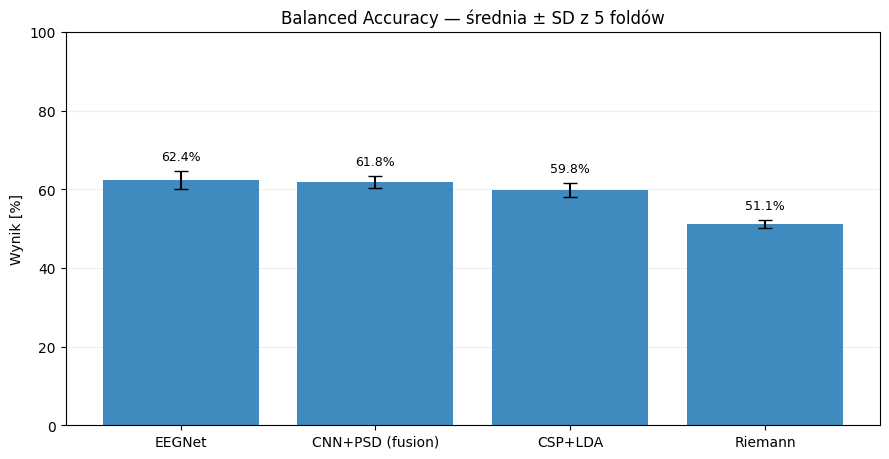

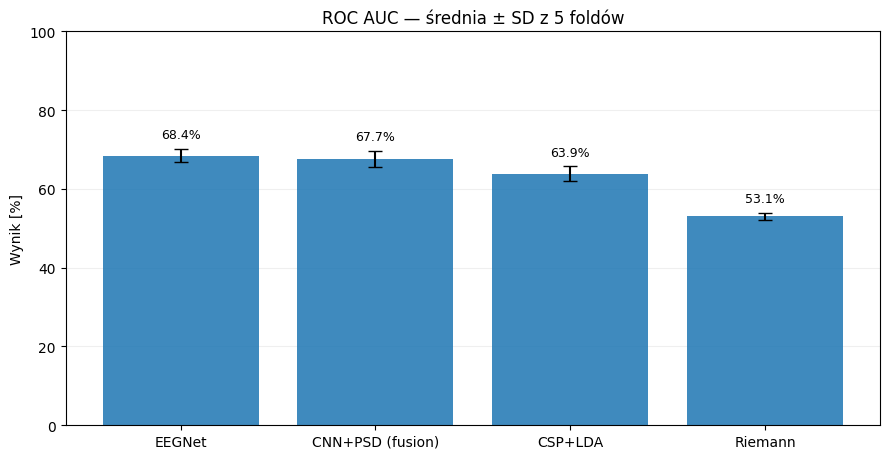

In [16]:
OUTPUT_DIR.mkdir(exist_ok=True, parents=True)
order = summary.index.tolist()
labels = [DISPLAY_NAMES[k] for k in order]


def plot_metric(metric, title, filename):
    means = summary.loc[order, f"{metric}_mean"].to_numpy(dtype=float) * 100
    sds = summary.loc[order, f"{metric}_sd"].fillna(0).to_numpy(dtype=float) * 100
    fig, ax = plt.subplots(figsize=(9, 4.7))
    x = np.arange(len(order))
    ax.bar(x, means, yerr=sds, capsize=5, alpha=0.86)
    ax.set_xticks(x, labels)
    ax.set_ylim(0, 100)
    ax.set_ylabel("Wynik [%]")
    ax.set_title(title + " — średnia ± SD z 5 foldów")
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    for i, val in enumerate(means):
        if np.isfinite(val):
            ax.text(i, min(99, val + (sds[i] if np.isfinite(sds[i]) else 0) + 2),
                    f"{val:.1f}%", ha="center", va="bottom", fontsize=9)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / filename, dpi=180, bbox_inches="tight")
    plt.show()


plot_metric("balanced_accuracy", "Balanced Accuracy", "01_balanced_accuracy.png")
plot_metric("roc_auc", "ROC AUC", "02_roc_auc.png")

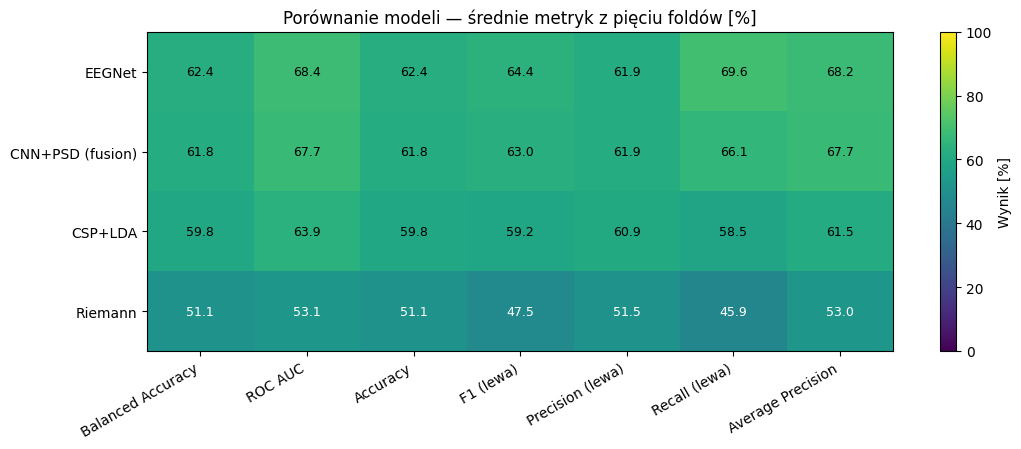

In [ ]:
heat_metrics = [m for m in ["balanced_accuracy", "roc_auc", "accuracy", "f1",
                             "precision", "recall", "average_precision"]
                if summary[f"{m}_mean"].notna().any()]
heat = np.array([[summary.loc[k, f"{m}_mean"] * 100 for m in heat_metrics]
                 for k in order], dtype=float)

fig, ax = plt.subplots(figsize=(11, 4.6))
img = ax.imshow(np.ma.masked_invalid(heat), aspect="auto", vmin=0, vmax=100, cmap="viridis")
ax.set_xticks(np.arange(len(heat_metrics)), [METRIC_LABELS[m] for m in heat_metrics], rotation=30, ha="right")
ax.set_yticks(np.arange(len(order)), labels)
for i in range(len(order)):
    for j in range(len(heat_metrics)):
        if np.isfinite(heat[i, j]):
            ax.text(j, i, f"{heat[i,j]:.1f}", ha="center", va="center",
                    color="white" if heat[i,j] < 55 else "black", fontsize=9)
ax.set_title("Porównanie modeli — średnie metryk z pięciu foldów [%]")
fig.colorbar(img, ax=ax, label="Wynik [%]")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "03_mapa_cieplna.png", dpi=180, bbox_inches="tight")
plt.show()

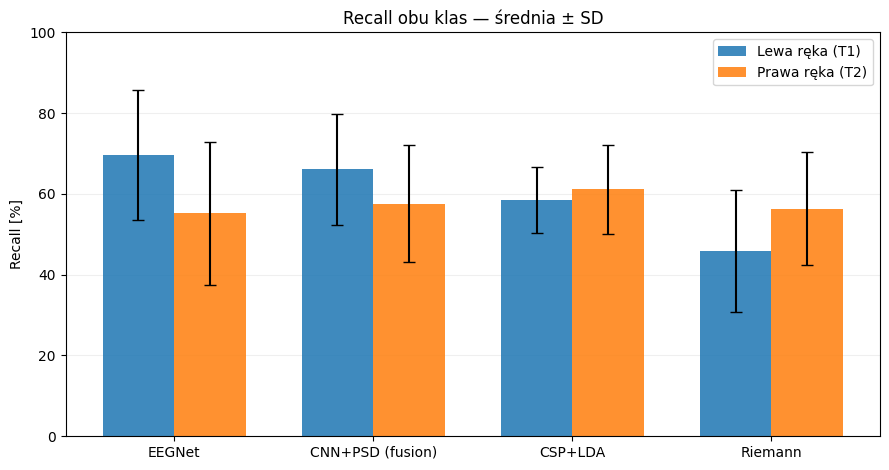

In [ ]:
if summary[["recall_mean", "recall_right_mean"]].notna().all().all():
    x = np.arange(len(order))
    width = 0.36
    fig, ax = plt.subplots(figsize=(9, 4.8))
    for shift, metric, lbl in [(-width/2, "recall", "Lewa ręka (T1)"),
                                (width/2, "recall_right", "Prawa ręka (T2)")]:
        means = summary.loc[order, f"{metric}_mean"].to_numpy() * 100
        sds = summary.loc[order, f"{metric}_sd"].fillna(0).to_numpy() * 100
        ax.bar(x+shift, means, width, yerr=sds, capsize=4, label=lbl, alpha=0.86)
    ax.set_xticks(x, labels)
    ax.set_ylim(0, 100)
    ax.set_ylabel("Recall [%]")
    ax.set_title("Recall obu klas — średnia ± SD")
    ax.legend()
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "04_recall_obu_rak.png", dpi=180, bbox_inches="tight")
    plt.show()
else:
    print("Pomijam wykres Recall obu klas — co najmniej jeden model nie ma wymaganych metryk.")

## 6. Kontrola identyczności foldów i różnice względem EEGNet

In [19]:
from itertools import combinations

fold_reference = frames["eegnet"].set_index("fold")
folds_ok = all(set(df["fold"]) == set(fold_reference.index) for df in frames.values())
counts_ok = all(
    "n_test" in df and "n_test" in fold_reference
    and (df.set_index("fold").loc[sorted(fold_reference.index), "n_test"].to_numpy()
         == fold_reference.loc[sorted(fold_reference.index), "n_test"].to_numpy()).all()
    for df in frames.values()
)

# Weryfikacja próbek, gdy w katalogach wyników dostępne są pełne predykcje
prediction_files = {m: paths[m].parent / "out_of_fold_predictions.csv" for m in frames}
all_predictions_exist = all(p.is_file() for p in prediction_files.values())
trial_check = None
if all_predictions_exist:
    example = None
    trial_check = True
    for model, p in prediction_files.items():
        pred = pd.read_csv(p, usecols=lambda c: c in {"trial_id", "fold", "y_true"})
        if not {"trial_id", "fold"}.issubset(pred.columns):
            trial_check = False
            break
        if pred["trial_id"].duplicated().any():
            trial_check = False
            break
        idx = pred.set_index("trial_id").sort_index()
        if example is None:
            example = idx
        elif not idx.index.equals(example.index) or not idx["fold"].equals(example["fold"]):
            trial_check = False
            break
        elif "y_true" in idx and "y_true" in example and not idx["y_true"].equals(example["y_true"]):
            trial_check = False
            break

print("Te same zestawy numerów foldów:", folds_ok)
print("Ta sama liczba epok testowych w odpowiednich foldach:", counts_ok)
if trial_check is None:
    print("Zgodność identyfikatorów epok: niezweryfikowana (brak kompletu plików predykcji).")
else:
    print("Identyczne epoki, foldy i dostępne etykiety:", trial_check)

paired_possible = folds_ok and counts_ok and (trial_check is not False)
if not paired_possible:
    warnings.warn("Nie można utworzyć poprawnego porównania sparowanego na foldach. "
                  "Tabela średnich z części 4 nadal jest dostępna.")
elif trial_check is None:
    warnings.warn("Różnice sparowane są tylko warunkowe: liczby epok są zgodne, "
                  "ale brak weryfikacji identyczności trial_id. Uzupełnij OOF CSV.")

Te same zestawy numerów foldów: True
Ta sama liczba epok testowych w odpowiednich foldach: True
Identyczne epoki, foldy i dostępne etykiety: True


In [ ]:
reference = "eegnet"
paired_rows = []
if paired_possible:
    for model in frames:
        if model == reference:
            continue
        a = frames[reference].set_index("fold").sort_index()
        b = frames[model].set_index("fold").sort_index()
        for metric in ["balanced_accuracy", "roc_auc", "f1", "recall", "recall_right"]:
            if metric not in a or metric not in b:
                continue
            differences = (b[metric] - a[metric]) * 100
            paired_rows.append({
                "model": model,
                "metryka": metric,
                "delta_mean_pp": differences.mean(),
                "delta_sd_pp": differences.std(ddof=1),
                "foldy_lepsze": int((differences > 0).sum()),
                "foldy_gorsze": int((differences < 0).sum()),
            })
    paired = pd.DataFrame(paired_rows)
    view = paired.copy()
    view["Model"] = view["model"].map(DISPLAY_NAMES)
    view["Metryka"] = view["metryka"].map(METRIC_LABELS)
    view["Zmiana (pp)"] = view.apply(
        lambda r: f"{r['delta_mean_pp']:+.2f} ± {r['delta_sd_pp']:.2f}", axis=1
    )
    view["Wygrane foldy"] = view["foldy_lepsze"].astype(str) + "/" + str(len(fold_reference))
    display(Markdown("### Różnice względem EEGNet — średnia ± SD [punkty procentowe]"))
    display(view[["Model", "Metryka", "Zmiana (pp)", "Wygrane foldy"]])
else:
    paired = pd.DataFrame()
    print("Brak zestawienia zmian sparowanych: podziały lub liczebności foldów nie są zgodne.")

### Różnice względem EEGNet — średnia ± SD [punkty procentowe]

,Model,Metryka,Zmiana (pp),Wygrane foldy
0,CNN+PSD (fusion),Balanced Accuracy,-0.56 ± 2.20,3/5
1,CNN+PSD (fusion),ROC AUC,-0.77 ± 1.88,2/5
2,CNN+PSD (fusion),F1 (lewa),-1.42 ± 3.70,2/5
3,CNN+PSD (fusion),Recall (lewa),-3.51 ± 6.87,2/5
4,CNN+PSD (fusion),Recall (prawa),+2.39 ± 6.03,4/5
5,CSP+LDA,Balanced Accuracy,-2.56 ± 1.55,0/5
6,CSP+LDA,ROC AUC,-4.56 ± 1.35,0/5
7,CSP+LDA,F1 (lewa),-5.20 ± 6.56,1/5
8,CSP+LDA,Recall (lewa),-11.05 ± 17.47,1/5
9,CSP+LDA,Recall (prawa),+5.94 ± 18.26,3/5


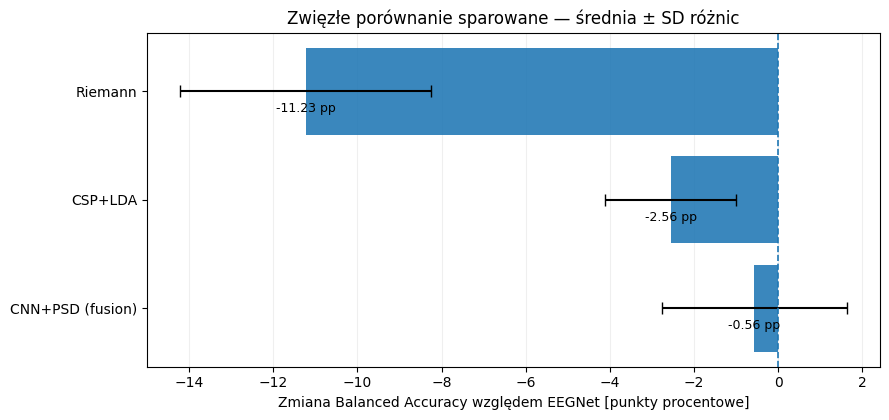

In [21]:
if not paired.empty:
    delta = paired[paired["metryka"] == "balanced_accuracy"].copy()
    if not delta.empty:
        delta = delta.set_index("model").loc[[m for m in frames if m != "eegnet"]].reset_index()
        y = np.arange(len(delta))
        fig, ax = plt.subplots(figsize=(9, 4.3))
        ax.barh(y, delta["delta_mean_pp"], xerr=delta["delta_sd_pp"],
                capsize=4, alpha=0.88)
        ax.axvline(0, linestyle="--", linewidth=1.2)
        ax.set_yticks(y, delta["model"].map(DISPLAY_NAMES))
        ax.set_xlabel("Zmiana Balanced Accuracy względem EEGNet [punkty procentowe]")
        ax.set_title("Zwięzłe porównanie sparowane — średnia ± SD różnic")
        ax.grid(axis="x", alpha=0.2)
        ax.set_axisbelow(True)
        for i, r in delta.iterrows():
            ax.text(r["delta_mean_pp"], i - 0.22, f"{r['delta_mean_pp']:+.2f} pp",
                    ha="center", va="bottom", fontsize=9)
        fig.tight_layout()
        fig.savefig(OUTPUT_DIR / "05_roznice_wzgledem_eegnet.png", dpi=180,
                    bbox_inches="tight")
        plt.show()

## 7. Eksport tabel i interpretacja naukowa

In [22]:
summary.to_csv(OUTPUT_DIR / "podsumowanie_liczbowe.csv", encoding="utf-8-sig")
pretty.to_csv(OUTPUT_DIR / "tabela_srednia_plus_sd.csv", encoding="utf-8-sig")
if not paired.empty:
    paired.to_csv(OUTPUT_DIR / "roznice_wzgledem_eegnet.csv", index=False,
                  encoding="utf-8-sig")
for model, df in frames.items():
    df.to_csv(OUTPUT_DIR / f"surowa_tabela_{model}.csv", index=False,
              encoding="utf-8-sig")

print("Zapisano raport w:", OUTPUT_DIR.resolve())
print("Pliki:")
for path in sorted(OUTPUT_DIR.iterdir()):
    if path.is_file():
        print(" -", path.name)

Zapisano raport w: /home/eliza/mgr-phd/porownanie_modeli
Pliki:
 - 01_balanced_accuracy.png
 - 02_roc_auc.png
 - 03_mapa_cieplna.png
 - 04_recall_obu_rak.png
 - 05_roznice_wzgledem_eegnet.png
 - podsumowanie_liczbowe.csv
 - roznice_wzgledem_eegnet.csv
 - surowa_tabela_cnn_psd.csv
 - surowa_tabela_csp_lda.csv
 - surowa_tabela_eegnet.csv
 - surowa_tabela_riemann.csv
 - tabela_srednia_plus_sd.csv
